# Models: Warendorfer Straße

Compares four forecasts of tomorrow's bicycle count with time-based cross-validation:

1. **Naive baseline:** same weekday one week earlier (`lag_7`)
2. **Holiday baseline:** naive baseline times a factor per kind of special day off
3. **Linear regression** on log(count)
4. **LightGBM** (gradient-boosted trees) on log(count)

Requires `python -m radmuenster` to have built the daily counts.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from radmuenster.evaluation import cross_validate, summarize, time_series_folds
from radmuenster.features import training_table
from radmuenster.models import (
    _lightgbm_inputs,
    _linear_inputs,
    _special_day_kind,
    fit_lightgbm,
    fit_linear,
    holiday_baseline,
    lightgbm,
    linear_regression,
    naive_baseline,
)
from radmuenster.weather import load_weather

daily = pd.read_parquet(Path("..") / "data" / "processed" / "daily_100034983.parquet")
weather = load_weather(cache_dir=Path("..") / "data" / "raw" / "weather")
table = training_table(daily, weather)
print(f"{len(table)} complete days, {table.shape[1] - 1} features, "
      f"{table.index.min():%Y-%m-%d} to {table.index.max():%Y-%m-%d}")

2551 complete days, 25 features, 2019-01-01 to 2026-10-09


## 1. Cross-validation folds

Each quarter from 2023 on is a test period; the model is trained on all days before it.
The model never sees the future it is evaluated on.

In [2]:
folds = pd.DataFrame([
    {"train_days": train.sum(), "test_start": table.index[test].min(),
     "test_end": table.index[test].max(), "test_days": test.sum()}
    for train, test in time_series_folds(table.index)
])
folds

,train_days,test_start,test_end,test_days
0,1319,2023-01-01,2023-03-30,86
1,1405,2023-04-01,2023-06-29,88
2,1493,2023-07-01,2023-09-29,88
3,1581,2023-10-01,2023-10-06,6
4,1587,2024-01-05,2024-03-29,83
5,1670,2024-04-01,2024-06-29,80
6,1750,2024-07-01,2024-09-29,89
7,1839,2024-10-01,2024-12-30,88
8,1927,2025-01-01,2025-03-30,87
9,2014,2025-04-01,2025-06-29,88


## 2. Overall comparison

In [3]:
MODELS = {
    "naive baseline": naive_baseline,
    "holiday baseline": holiday_baseline,
    "linear regression": linear_regression,
    "LightGBM": lightgbm,
}
predictions = {name: cross_validate(model, table) for name, model in MODELS.items()}

overall = pd.concat({name: summarize(p).iloc[0] for name, p in predictions.items()}, axis=1).T
overall["n_days"] = overall["n_days"].astype(int)
overall.style.format({"mae": "{:.0f}", "wape": "{:.1%}", "mape": "{:.1%}", "nrmse": "{:.1%}"})

,n_days,mae,wape,mape,nrmse
naive baseline,1232,960,16.1%,24.0%,23.3%
holiday baseline,1232,848,14.3%,17.7%,18.9%
linear regression,1232,646,10.9%,12.1%,14.4%
LightGBM,1232,529,8.9%,10.2%,12.0%


MAE is in bicycle trips, WAPE is the sum of errors divided by the sum of actual counts.
MAPE is dominated by days with very few trips (snow), NRMSE by a few large errors.

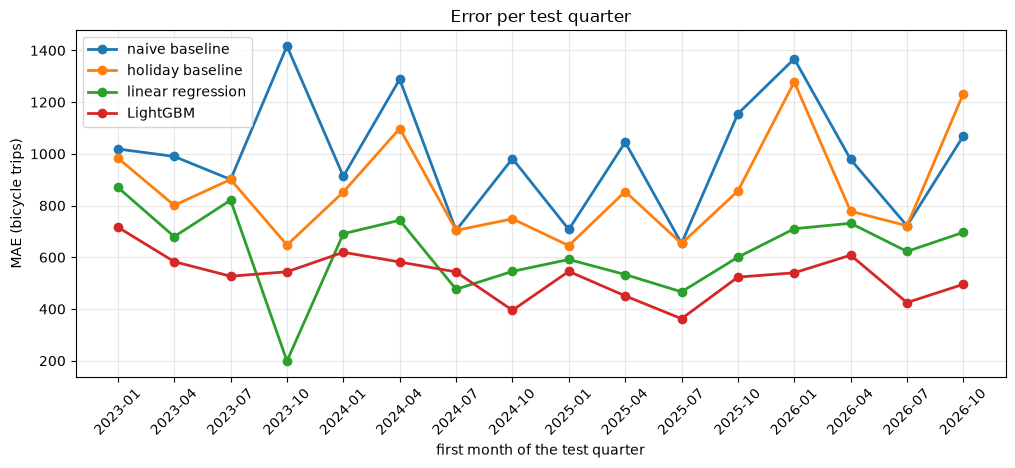

In [4]:
# One colour per model, the same in every plot
COLORS = dict(zip(MODELS, plt.cm.tab10.colors))

by_fold = pd.DataFrame({name: summarize(p, by="fold")["mae"] for name, p in predictions.items()})
by_fold.index = folds["test_start"].dt.strftime("%Y-%m").to_numpy()

fig, ax = plt.subplots(figsize=(12, 4.5))
for name in MODELS:
    ax.plot(by_fold.index, by_fold[name], marker="o", lw=2, color=COLORS[name], label=name)
ax.set_ylabel("MAE (bicycle trips)")
ax.set_xlabel("first month of the test quarter")
ax.set_title("Error per test quarter")
ax.tick_params(axis="x", rotation=45)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

The folds starting 2023-10 and 2026-10 have only 6 and 9 test days (inbound outage, current quarter),
so their error is noisy. The overall metrics above count every day once instead.

## 3. Error by kind of day

In [5]:
kind = _special_day_kind(table).fillna("regular day").rename("kind")
by_kind = pd.DataFrame({name: summarize(p, by=kind.loc[p.index])["mae"] for name, p in predictions.items()})
by_kind.insert(0, "days", summarize(predictions["LightGBM"], by=kind.loc[predictions["LightGBM"].index])["n_days"].astype(int))
by_kind.round(0)

,days,naive baseline,holiday baseline,linear regression,LightGBM
kind,,,,,
is_bridge_day,12,1521.0,1518.0,636.0,800.0
is_christmas,9,3102.0,746.0,333.0,312.0
is_holiday,37,4113.0,1152.0,570.0,513.0
is_rosenmontag,4,2630.0,896.0,641.0,656.0
regular day,1170,832.0,832.0,651.0,528.0


In [6]:
snow = (table.loc[predictions["LightGBM"].index, "snow_recent"] > 0).map({True: "snow in the last 5 days", False: "no snow"})
pd.DataFrame({name: summarize(p, by=snow)["mae"] for name, p in predictions.items()}).round(0)

,naive baseline,holiday baseline,linear regression,LightGBM
snow_recent,,,,
no snow,926.0,820.0,599.0,494.0
snow in the last 5 days,1119.0,980.0,867.0,695.0


## 4. Forecast and actual counts, winter 2025/26

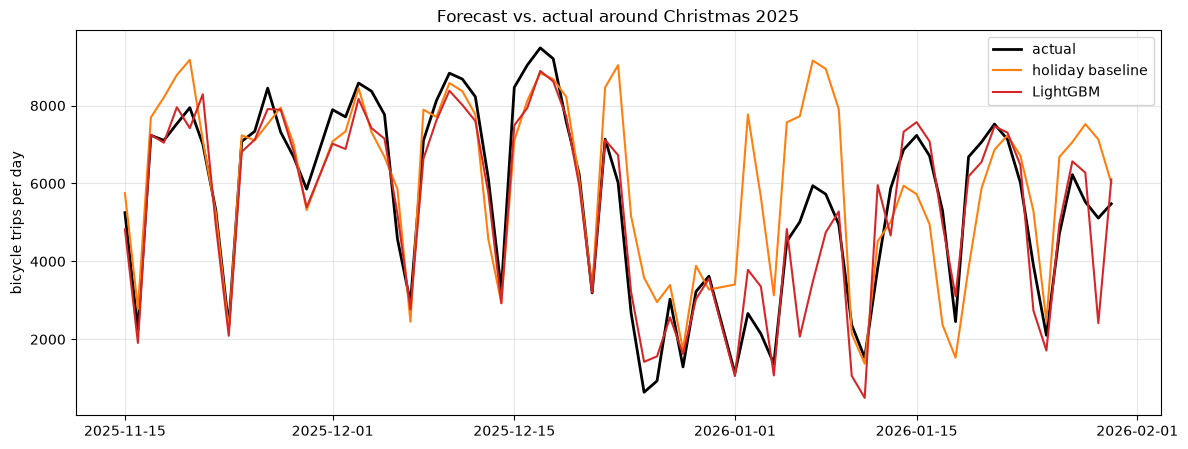

In [7]:
window = slice("2025-11-15", "2026-01-31")
actual = predictions["LightGBM"].loc[window, "actual"]

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(actual.index, actual, color="black", lw=2, label="actual")
for name in ["holiday baseline", "LightGBM"]:
    ax.plot(actual.index, predictions[name].loc[window, "predicted"], lw=1.5, color=COLORS[name], label=name)
ax.set_ylabel("bicycle trips per day")
ax.set_title("Forecast vs. actual around Christmas 2025")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 5. What the linear regression learned

The coefficients refer to log(count), so a coefficient *c* per unit means "× e^c".
Converted to a factor per unit (for example per public holiday or per hour of rain), they can be read directly.

In [8]:
pipeline, weekday_median = fit_linear(table)
prepare = pipeline.named_steps["prepare"]
coef = pd.Series(pipeline.named_steps["regression"].coef_, index=prepare.get_feature_names_out())

# Undo the standardisation: coefficient per unit = coefficient per standard deviation / standard deviation
scaler = prepare.named_transformers_["scale"]
scaled = [f"scale__{name}" for name in scaler.feature_names_in_]
coef[scaled] = coef[scaled].to_numpy() / scaler.scale_

# Weekdays relative to their mean, so that the factors read "compared to an average day"
weekdays = [f"onehot__weekday_{d}" for d in range(7)]
coef[weekdays] -= coef[weekdays].mean()

labels = {
    **{f"onehot__weekday_{d}": f"weekday: {day}" for d, day in enumerate(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])},
    "scale__is_holiday": "public holiday", "scale__is_christmas": "24-31 December",
    "scale__is_rosenmontag": "Rosenmontag", "scale__is_bridge_day": "bridge day",
    "scale__is_school_holiday": "school holidays", "scale__is_lecture_period": "lecture period",
    "scale__precipitation_hours": "per hour of precipitation", "scale__temp_max": "per °C maximum temperature",
    "scale__sunshine": "per hour of sunshine", "scale__wind_max": "per km/h maximum wind",
    "scale__log_snow_recent": "per log(1 + cm) snow in 5 days",
}
factors = np.exp(coef[list(labels)]).rename(index=labels)
factors.to_frame("factor").style.format("× {:.2f}")

,factor
weekday: Mon,× 1.12
weekday: Tue,× 1.19
weekday: Wed,× 1.26
weekday: Thu,× 1.19
weekday: Fri,× 1.14
weekday: Sat,× 0.92
weekday: Sun,× 0.48
public holiday,× 0.42
24-31 December,× 0.50
Rosenmontag,× 0.75


## 6. What LightGBM relies on

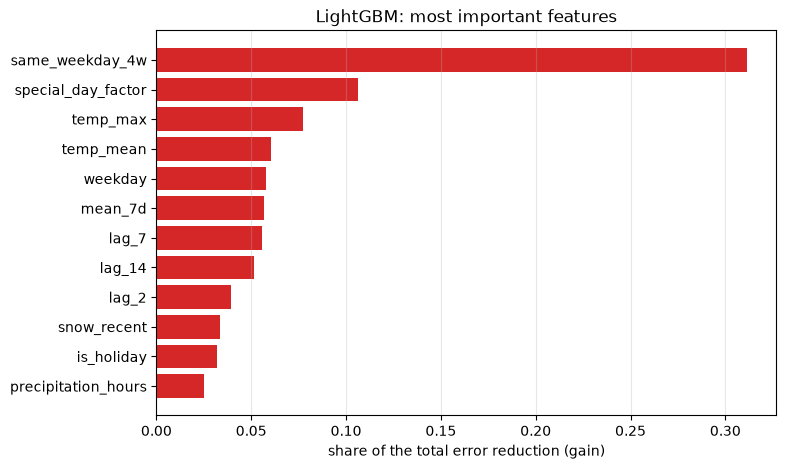

,special day factor (whole data)
is_bridge_day,0.96
is_christmas,0.51
is_holiday,0.39
is_rosenmontag,0.58


In [9]:
model, special_factors = fit_lightgbm(table)
gain = pd.Series(model.booster_.feature_importance("gain"), index=model.booster_.feature_name())
share = (gain / gain.sum()).sort_values().tail(12)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(share.index, share, color=COLORS["LightGBM"])
ax.set_xlabel("share of the total error reduction (gain)")
ax.set_title("LightGBM: most important features")
ax.grid(axis="x", alpha=0.3)
plt.show()
special_factors.round(2).to_frame("special day factor (whole data)")

## Findings

- **LightGBM is the best model:** MAE 529 trips, WAPE 8.9 %. That is 45 % less error than the naive baseline
  (960, 16.1 %) and 18 % less than the linear regression (646, 10.9 %). It has the lowest error in every test
  quarter except the one with only 6 test days.
- **Special days:** the naive baseline misses public holidays by about 4,100 trips. A factor per kind of day
  (holiday × 0.39, Christmas × 0.51, Rosenmontag × 0.58, bridge day × 0.96) cuts this to about 1,150.
  LightGBM alone could not learn rare days such as Rosenmontag, because a leaf needs at least 20 days;
  giving it these factors as a feature fixed that.
- **Around Christmas** the holiday baseline overshoots in early January (school holidays and lecture break
  still running); the models know both and follow the actual counts.
- **Snow** is still the hardest case: LightGBM's error is about 40 % higher on days with snow in the last 5 days.
- **The linear regression is readable:** compared to an average day, Sundays have × 0.48, public holidays
  × 0.42, school holidays × 0.92; each hour of precipitation costs about 1 %, each degree of maximum
  temperature adds about 1 %.
- **These errors are a lower bound for the app:** the cross-validation uses the measured weather of the
  forecast day, the app will only have a weather forecast.